# HPC job telemetry and resource rightsizing

Robust queue, scaling, efficiency, and common-job-name plots for the Slurm registry.

In [6]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({"figure.dpi": 150, "axes.spines.top": False, "axes.spines.right": False})
registry = Path("../telemetry/job_resource_registry.csv")
if not registry.exists():
    registry = Path("telemetry/job_resource_registry.csv")
df = pd.read_csv(registry, low_memory=False, dtype={"job_id": "string"})
numeric = ["n_transients", "req_mem_gb", "used_max_rss_gb", "mem_efficiency_pct", "queue_wait_min", "used_walltime_hours", "submit_hour", "output_storage_mb"]
df[numeric] = df[numeric].apply(pd.to_numeric, errors="coerce")
print(f"Loaded {len(df):,} records")
model_colors = {"Metzger": "#4C72B0", "Bu2026Fixed": "#55A868", "Bu2026Vary": "#C44E52"}

def positive(*columns):
    mask = pd.Series(True, index=df.index)
    for column in columns:
        mask &= df[column].notna() & np.isfinite(df[column]) & (df[column] > 0)
    return df.loc[mask]


Loaded 23,480 records


## Queue behavior

[Text(0.5, 0, 'Submission hour'),
 Text(0, 0.5, 'Queue wait [minutes]'),
 Text(0.5, 1.0, 'Typical wait by hour')]

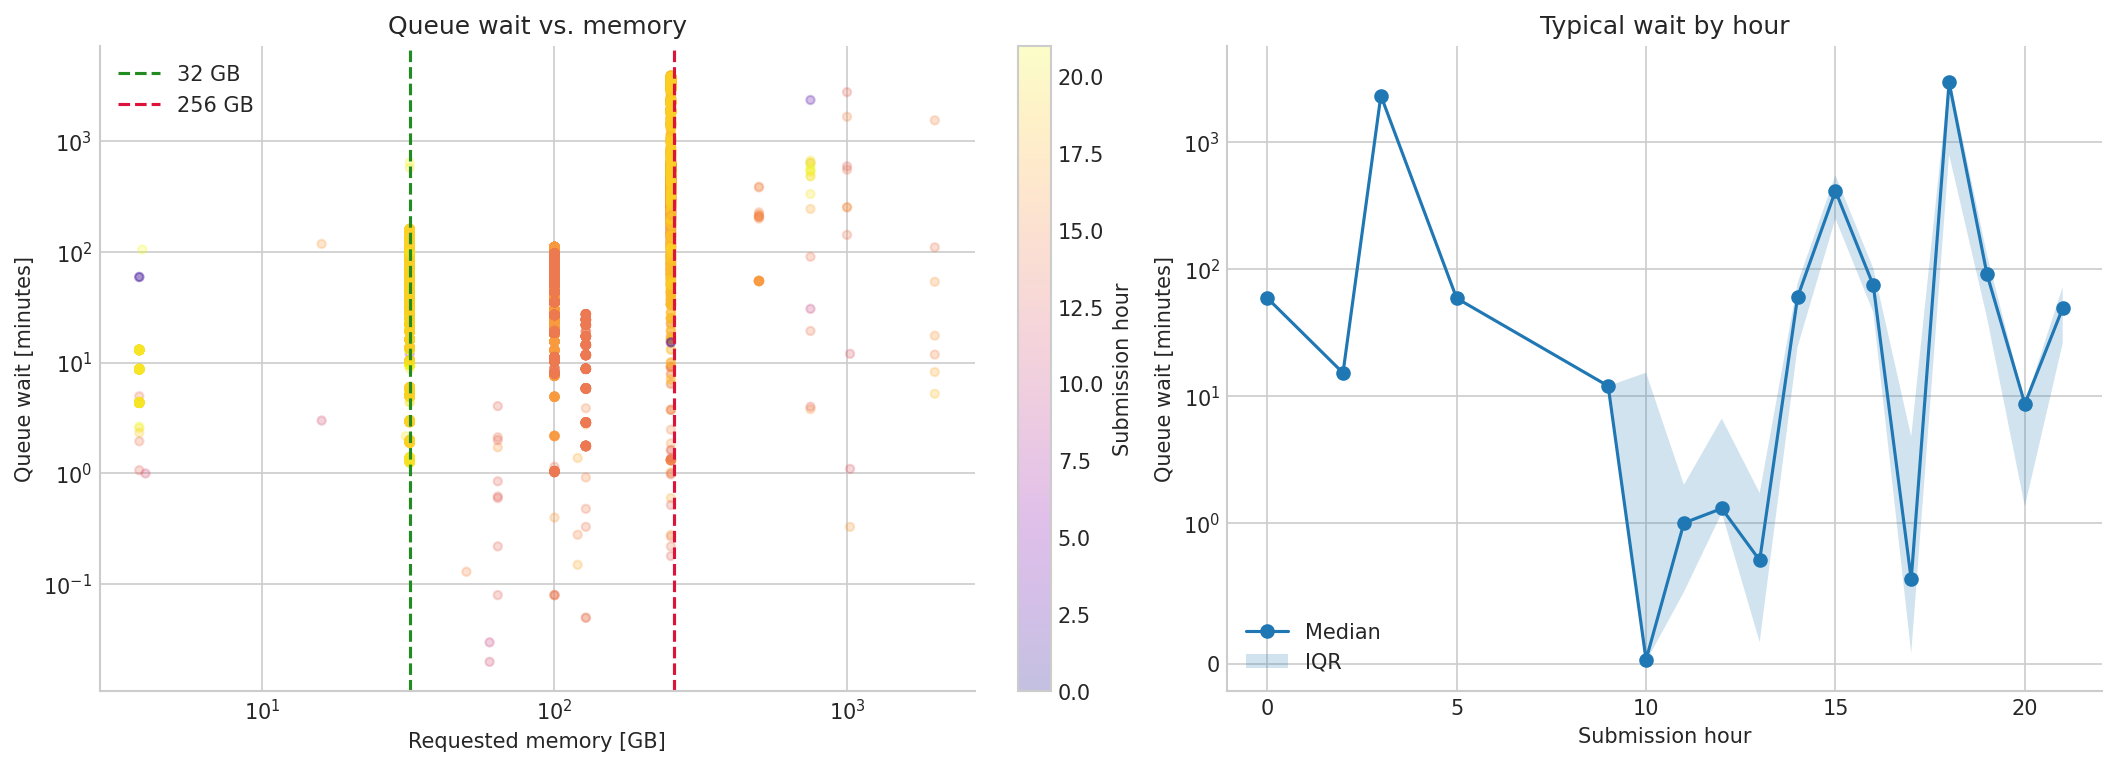

In [2]:
queue = positive("req_mem_gb", "queue_wait_min")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
if not queue.empty:
    sc = ax1.scatter(queue["req_mem_gb"], queue["queue_wait_min"], c=queue["submit_hour"].fillna(0), cmap="plasma", s=16, alpha=.25, rasterized=True)
    fig.colorbar(sc, ax=ax1, label="Submission hour")
    ax1.set_xscale("log")
    ax1.set_yscale("log")
    ax1.axvline(32, color="forestgreen", ls="--", label="32 GB")
    ax1.axvline(256, color="crimson", ls="--", label="256 GB")
    ax1.legend()
ax1.set(xlabel="Requested memory [GB]", ylabel="Queue wait [minutes]", title="Queue wait vs. memory")
hourly = df[df["queue_wait_min"].notna() & df["submit_hour"].notna() & (df["queue_wait_min"] >= 0)]
if not hourly.empty:
    q = hourly.groupby("submit_hour")["queue_wait_min"].quantile([.25, .5, .75]).unstack()
    q = q.reindex(range(24))
    valid = q[.5].notna()
    ax2.plot(q.index[valid], q.loc[valid, .5], marker="o", label="Median")
    ax2.fill_between(q.index[valid], q.loc[valid, .25], q.loc[valid, .75], alpha=.2, label="IQR")
    ax2.set_yscale("symlog", linthresh=1)
    ax2.legend()
ax2.set(xlabel="Submission hour", ylabel="Queue wait [minutes]", title="Typical wait by hour")


## Scaling, efficiency, and common job names

[Text(0.5, 0, 'Requested memory [GB]'),
 Text(0, 0.5, 'Efficiency [%]'),
 Text(0.5, 1.0, 'Memory efficiency')]

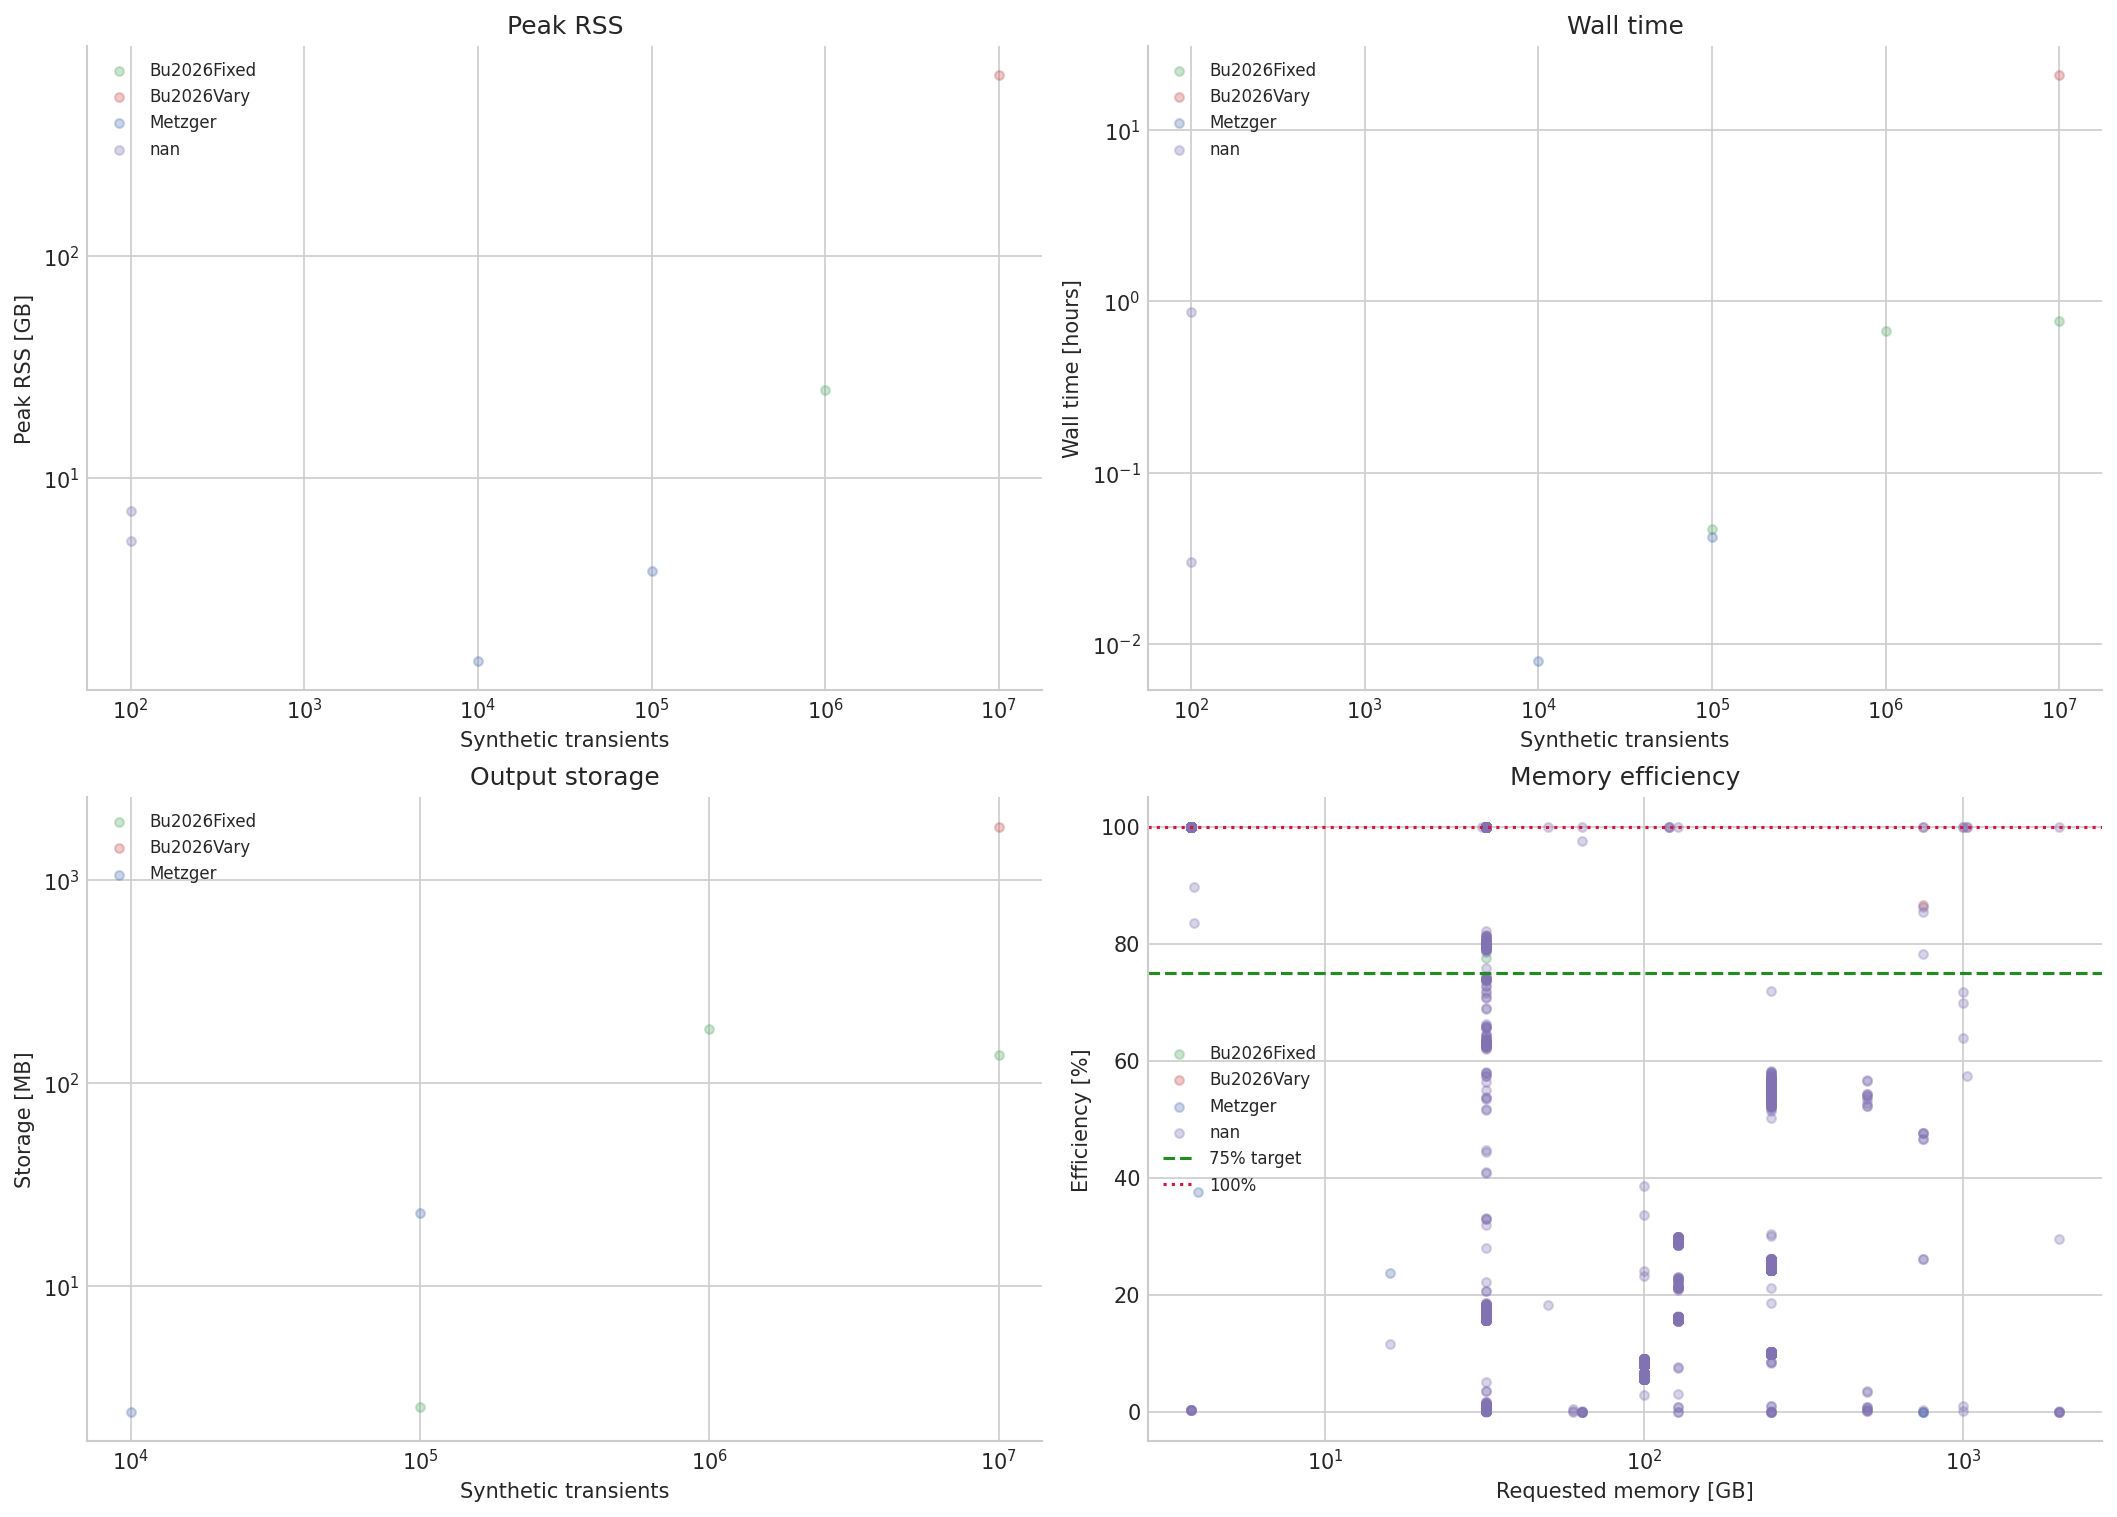

In [3]:
scaling = positive("n_transients")
fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)
for model, group in scaling.groupby("model", dropna=False):
    label = str(model)
    color = model_colors.get(label, "#8172B2")
    for ax, column, title, ylabel in [
        (axes[0, 0], "used_max_rss_gb", "Peak RSS", "Peak RSS [GB]"),
        (axes[0, 1], "used_walltime_hours", "Wall time", "Wall time [hours]"),
        (axes[1, 0], "output_storage_mb", "Output storage", "Storage [MB]"),
    ]:
        valid = group[group[column].notna() & np.isfinite(group[column]) & (group[column] > 0)]
        if not valid.empty:
            ax.scatter(valid["n_transients"], valid[column], s=18, alpha=.3, color=color, label=label, rasterized=True)
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set(xlabel="Synthetic transients", ylabel=ylabel, title=title)
        ax.legend(fontsize=8)
eff = positive("req_mem_gb", "used_max_rss_gb")
eff = eff[eff["mem_efficiency_pct"].between(0, 110)]
if not eff.empty:
    for model, group in eff.groupby("model", dropna=False):
        label = str(model)
        axes[1, 1].scatter(group["req_mem_gb"], group["mem_efficiency_pct"], s=18, alpha=.3, label=label, color=model_colors.get(label, "#8172B2"), rasterized=True)
    axes[1, 1].set_xscale("log")
    axes[1, 1].axhline(75, color="forestgreen", ls="--", label="75% target")
    axes[1, 1].axhline(100, color="crimson", ls=":", label="100%")
    axes[1, 1].legend(fontsize=8)
axes[1, 1].set(xlabel="Requested memory [GB]", ylabel="Efficiency [%]", title="Memory efficiency")


{'estimated_peak_rss_gb': 94.0, 'estimated_walltime_hours': 0.61, 'observations_used': 2}


/tmp/ipykernel_3764121/2418158341.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax2.boxplot(groups, vert=False, labels=order, showfliers=False, patch_artist=True, boxprops={"facecolor": "#55A868"})


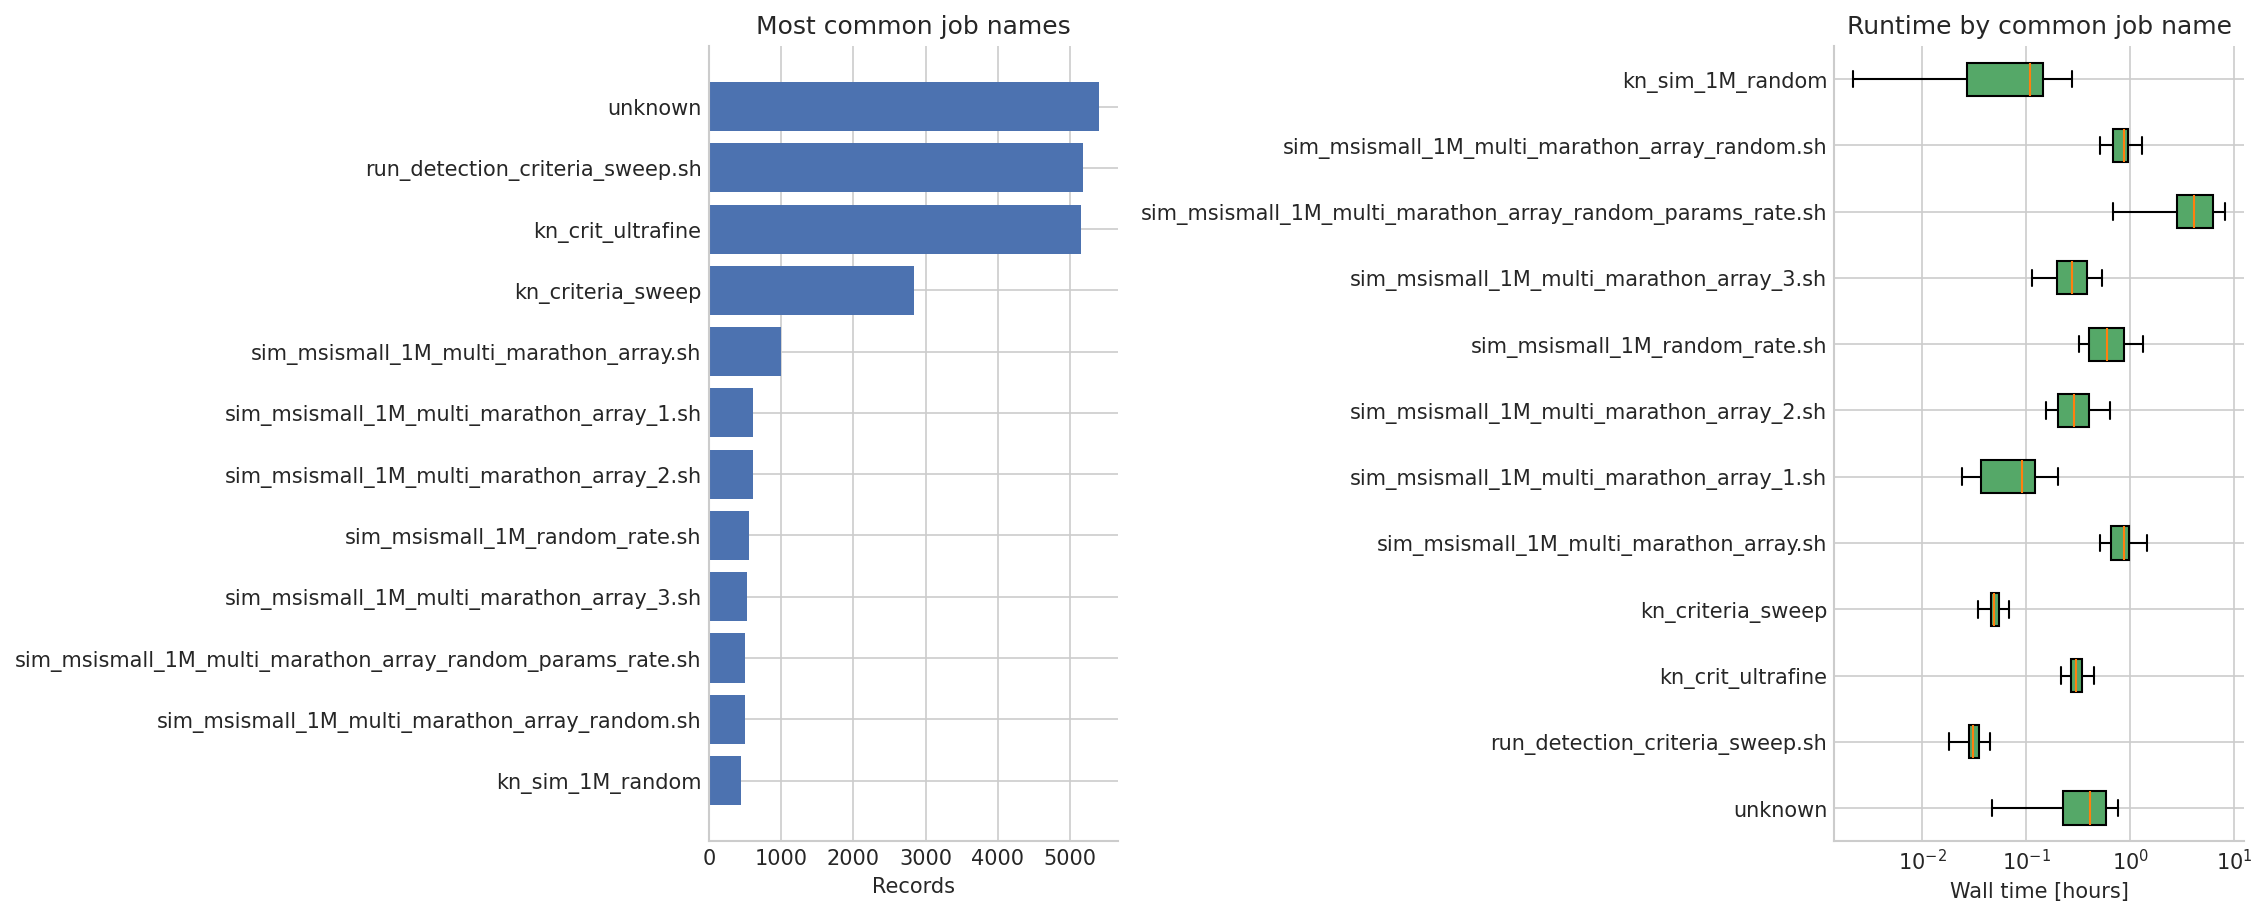

In [7]:
jobs = df[["job_name", "used_walltime_hours"]].copy()
jobs["job_name"] = jobs["job_name"].fillna("unknown").astype(str).str.strip().str.replace(r"^.*/", "", regex=True)
jobs.loc[jobs["job_name"].isin(["", "nan", "None"]), "job_name"] = "unknown"
top = jobs["job_name"].value_counts().head(12).sort_values()
common = jobs[jobs["job_name"].isin(top.index)].copy()
common["runtime"] = pd.to_numeric(common["used_walltime_hours"], errors="coerce")
common = common[common["runtime"].notna() & (common["runtime"] > 0)]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)
ax1.barh(top.index, top.values, color="#4C72B0")
ax1.set(xlabel="Records", title="Most common job names")
if not common.empty:
    order = top.index[::-1]
    groups = [common.loc[common["job_name"] == name, "runtime"] for name in order]
    ax2.boxplot(groups, vert=False, labels=order, showfliers=False, patch_artist=True, boxprops={"facecolor": "#55A868"})
    ax2.set_xscale("symlog", linthresh=.01)
ax2.set(xlabel="Wall time [hours]", title="Runtime by common job name")

def estimate_resources(n_transients, model=None):
    sample = positive("n_transients", "used_max_rss_gb", "used_walltime_hours")
    if model is not None:
        filtered = sample[sample["model"].astype(str) == str(model)]
        if not filtered.empty:
            sample = filtered
    rss = (sample["used_max_rss_gb"] / sample["n_transients"]).median() * n_transients
    hours = (sample["used_walltime_hours"] / sample["n_transients"]).median() * n_transients
    return {"estimated_peak_rss_gb": float(rss), "estimated_walltime_hours": float(hours), "observations_used": len(sample)}

print(estimate_resources(1_000_000, "Metzger"))


## Additional diagnostics

These views separate scheduling effects from workload effects: job outcomes, CPU/memory utilization together, requested-versus-used resources, and queue wait by weekday and hour.

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)
states = df["state"].fillna("UNKNOWN").astype(str).str.replace(r"\s+by\s+.*$", "", regex=True).value_counts()
axes[0, 0].barh(states.index[::-1], states.values[::-1], color="#C44E52")
axes[0, 0].set(xlabel="Job records", title="Job outcome mix")

util = df[["cpu_efficiency_pct", "mem_efficiency_pct", "model"]].copy()
util[["cpu_efficiency_pct", "mem_efficiency_pct"]] = util[["cpu_efficiency_pct", "mem_efficiency_pct"]].apply(pd.to_numeric, errors="coerce")
util = util.replace([np.inf, -np.inf], np.nan).dropna()
util = util[util["cpu_efficiency_pct"].between(0, 110) & util["mem_efficiency_pct"].between(0, 110)]
for model, group in util.groupby("model", dropna=False):
    name = str(model)
    axes[0, 1].scatter(group["cpu_efficiency_pct"], group["mem_efficiency_pct"], s=18, alpha=.25, label=name, color=model_colors.get(name, "#8172B2"), rasterized=True)
axes[0, 1].axvline(75, color="gray", ls="--", lw=1)
axes[0, 1].axhline(75, color="gray", ls="--", lw=1)
axes[0, 1].set(xlabel="CPU efficiency [%]", ylabel="Memory efficiency [%]", title="CPU vs. memory efficiency")
axes[0, 1].legend(fontsize=8)

requested = positive("req_mem_gb", "used_max_rss_gb")
if not requested.empty:
    axes[1, 0].scatter(requested["req_mem_gb"], requested["used_max_rss_gb"], s=16, alpha=.22, color="#4C72B0", rasterized=True)
    limit = max(requested["req_mem_gb"].max(), requested["used_max_rss_gb"].max())
    axes[1, 0].plot([.01, limit], [.01, limit], color="crimson", ls="--", label="Requested = used")
    axes[1, 0].set_xscale("log")
    axes[1, 0].set_yscale("log")
    axes[1, 0].legend(fontsize=8)
axes[1, 0].set(xlabel="Requested memory [GB]", ylabel="Peak RSS [GB]", title="Memory allocation headroom")

heat = df[df["queue_wait_min"].notna() & df["submit_hour"].notna() & df["submit_day_of_week"].notna()].copy()
if not heat.empty:
    day_order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
    table = heat.pivot_table(index="submit_day_of_week", columns="submit_hour", values="queue_wait_min", aggfunc="median").reindex(index=day_order, columns=range(24))
    norm = plt.matplotlib.colors.SymLogNorm(linthresh=1, vmin=0, vmax=max(1, np.nanmax(table.to_numpy())))
    image = axes[1, 1].imshow(table, aspect="auto", interpolation="nearest", cmap="magma", norm=norm)
    axes[1, 1].set_yticks(range(len(day_order)), day_order)
    axes[1, 1].set_xticks(range(0, 24, 2))
    fig.colorbar(image, ax=axes[1, 1], label="Median wait [minutes]")
axes[1, 1].set(xlabel="Submission hour", ylabel="Day", title="Median queue wait heatmap")
plt.show()
